# NB2 · Mean squared displacement: from equations of motion to data

The **mean squared displacement (MSD)** asks: how far does a cell get, on average, in a time $\tau$? Its shape as a function of $\tau$ is a fingerprint of the navigation strategy. This notebook (part **D**: from kinematics back to space) compares three models:

| model | rule | what we can compute |
|---|---|---|
| **Brownian motion** | a non-swimming cell, pushed by random molecular kicks | exact MSD |
| **Run-and-tumble with OU switching** | swim straight, tumble, repeat; the tumble rate of each cell drifts slowly | exact MSD for a *constant* rate; simulation for the drifting rate |
| **Biased random walk** | run-and-tumble in an attractant gradient | approximate MSD; simulation |

For each model: its **equation of motion**, **example tracks**, and its **MSD** from theory and from simulation. Section 7 then computes the MSD of the synthetic datasets, which have short, noisy tracks like real data.

Sections 2–5 use long, perfectly measured simulated tracks (600 s each, 800 tracks per model), so the curves show the models, not the limits of measurement. Two stops marked **🔧 Try it** are for hands-on work; each changes only the cells right below it.

## 0 · Setup
Run this cell first. It loads the packages and the course package `motility` from the folder above `notebooks/`.

In [1]:
import os, sys
sys.path.insert(0, os.path.abspath(".."))   # the course package `motility` is in the folder above notebooks/

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from motility import io, plotting
from motility import analysis as an
from motility import simulate as sim
from motility.plotting import COLORS, STYLE, GRAY, THEORY_KW

plotting.set_style()
rng = np.random.default_rng(5910)   # fixed seed: everyone gets the same figures

In [2]:
# ---- simulation settings
FPS = 30.0                    # frames per second
T = 600.0                     # s per simulated track (real tracks are ~10 s)
BATCH, N_BATCHES = 100, 8     # MSDs average over 800 tracks
LAGS = an.log_lags(int(0.1 * T * FPS))           # 1 frame ... 60 s
TAU = LAGS / FPS
TAU_FINE = np.logspace(np.log10(TAU[0]), np.log10(TAU[-1]), 300)

# ---- model parameters (E. coli-like)
D_B = 0.35                    # µm²/s, non-swimming cell
V = 25.0                      # µm/s, swimming speed
LAM = 1.0                     # 1/s, tumble rate
DR = 0.15                     # rad²/s, rotational diffusion during runs
TURN = (68.0, 36.0)           # turn angle at a tumble: |normal(68°, 36°)|
OU_SIGMA, OU_TAU = 1.0, 10.0  # OU switching: size and correlation time (s) of the rate fluctuations
GRADIENT = 0.7                # strength of the chemotactic bias
SWIM = dict(speed=V, run_rate=LAM, Dr=DR, turn_angle=TURN, tumble_time=0, substeps=1)   # instantaneous tumbles

COS_PHI = sim.turn_angle_cos(TURN)
TAU_P = 1 / (LAM * (1 - COS_PHI) + DR)           # persistence time (section 3)
D_EFF = V**2 * TAU_P / 2                          # long-time diffusion coefficient of a swimmer
print(f"<cos φ> = {COS_PHI:.2f},  τ_p = {TAU_P:.2f} s,  D_eff = {D_EFF:.0f} µm²/s")

def msd_of(simulate):
    """MSD averaged over N_BATCHES batches of BATCH simulated tracks."""
    return an.msd_many(simulate, LAGS, N_BATCHES)

<cos φ> = 0.31,  τ_p = 1.19 s,  D_eff = 371 µm²/s


## 1 · What the MSD measures

For a lag $\tau$,
$$\mathrm{MSD}(\tau)=\big\langle\,|\mathbf r(t+\tau)-\mathbf r(t)|^2\,\big\rangle ,$$
averaged over all start times $t$ and all cells. On log-log axes a power law $\mathrm{MSD}\propto\tau^{\alpha}$ is a straight line of slope $\alpha$, so we also plot the **local exponent** $\alpha(\tau)=d\log\mathrm{MSD}/d\log\tau$:

| $\alpha$ | name | picture |
|---|---|---|
| 1 | diffusive | wandering: distance grows like $\sqrt\tau$ |
| 2 | ballistic | straight line: distance grows like $\tau$ |

**How an equation of motion becomes an MSD.** Over a lag $\tau$ the displacement is a sum of $N=\tau/\Delta t$ frame-to-frame steps, so
$$\mathrm{MSD}(\tau)=\sum_{n=1}^{N}\sum_{m=1}^{N}\big\langle\Delta\mathbf r_n\cdot\Delta\mathbf r_m\big\rangle .$$
The diagonal terms ($n=m$) are each step's size squared. The cross terms ($n\neq m$) ask whether steps are **correlated**: the velocity autocorrelation of NB1. Each model gives a different answer.

## 2 · Brownian motion (analytic)

**Equation of motion.** A non-swimming cell gets independent random kicks:
$$\dot{\mathbf r}=\sqrt{2D}\,\boldsymbol\eta(t)
\qquad\text{simulated as}\qquad
\mathbf r_{n+1}=\mathbf r_n+\sqrt{2D\,\Delta t}\;\boldsymbol\xi_n ,\quad \boldsymbol\xi_n\sim\mathcal N(0,\mathbb 1).$$

**MSD.** Independent steps, so every cross term is zero. Each step contributes $2\times2D\Delta t$ (two dimensions):
$$\boxed{\mathrm{MSD}(\tau)=4D\tau}\qquad\alpha=1\text{ at every lag.}$$
Variances of independent steps add; that is why diffusion is linear in time. For a 1 µm bacterium in water, $D\approx0.35$ µm²/s.

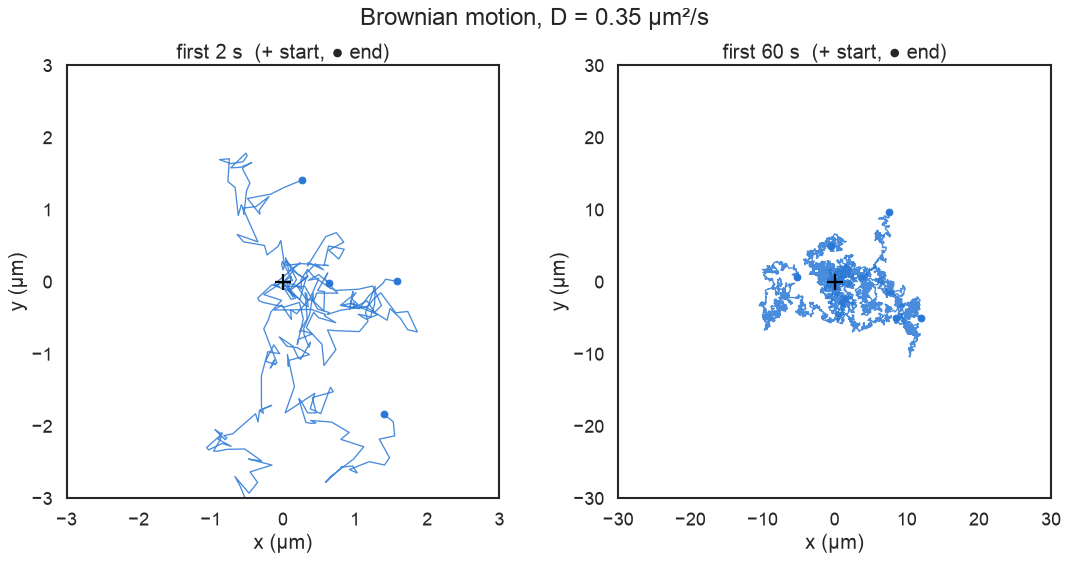

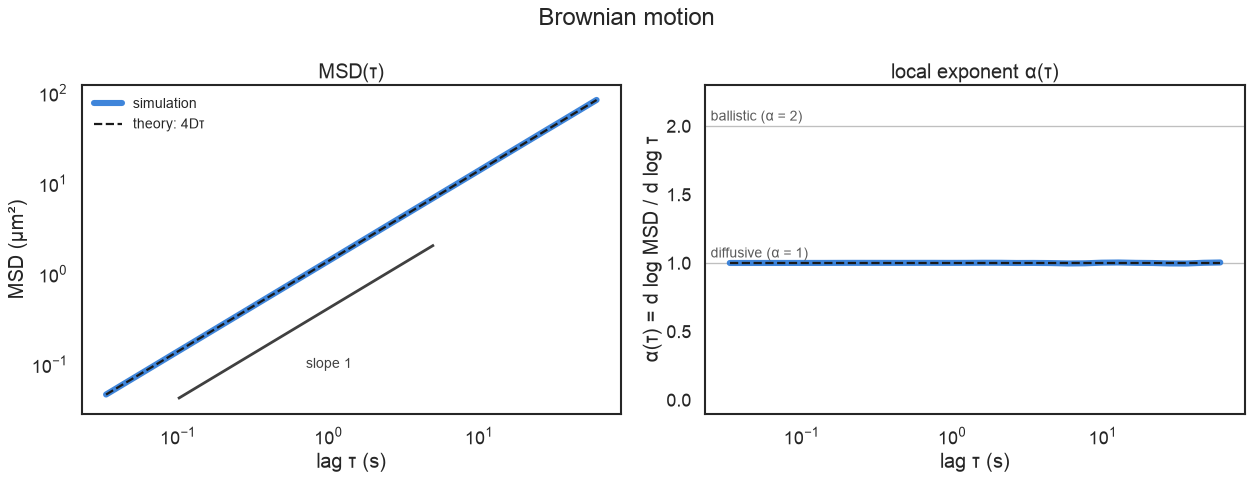

In [3]:
sim_b = lambda: sim.simulate_brownian(BATCH, T, FPS, D_B, rng)
tracks_b = sim_b()
plotting.plot_tracks(tracks_b, FPS, COLORS["brownian"], f"Brownian motion, D = {D_B} µm²/s", lims=(3, 30))

msd_b = msd_of(sim_b)
plotting.msd_figure([(TAU, msd_b, STYLE["brownian"], "simulation")],
                    theory=[(TAU_FINE, an.msd_brownian(TAU_FINE, D_B), "theory: 4Dτ")],
                    slopes=[(1, 0.1, 5)], title="Brownian motion")

## 3 · Run-and-tumble with a constant tumble rate (analytic)

**Equation of motion.** The cell swims at speed $v$ along its heading $\theta$: $\dot{\mathbf r}=v\,\hat{\mathbf e}(\theta)$, $\hat{\mathbf e}=(\cos\theta,\sin\theta)$. During runs the heading wobbles, $\dot\theta=\sqrt{2D_r}\,\xi(t)$. At rate $\lambda$ the cell tumbles and turns by an angle $\varphi$ (instantaneously, here).

**MSD.** Steps less than about $\tau_p$ apart point the same way, so the cross terms are not zero. The velocity autocorrelation decays as $v^2e^{-\tau/\tau_p}$ with the **persistence time**
$$\tau_p=\frac{1}{\lambda\,(1-\langle\cos\varphi\rangle)+D_r},$$
and summing the cross terms gives
$$\boxed{\mathrm{MSD}(\tau)=2v^2\tau_p^2\left(\frac{\tau}{\tau_p}-1+e^{-\tau/\tau_p}\right)}
\qquad
\begin{cases}\tau\ll\tau_p: & \mathrm{MSD}\approx v^2\tau^2 & (\alpha=2,\ \text{ballistic})\\[2pt]
\tau\gg\tau_p: & \mathrm{MSD}\approx 4D_\text{eff}\,\tau,\ \ D_\text{eff}=v^2\tau_p/2 & (\alpha=1,\ \text{diffusive})\end{cases}$$
A swimmer is ballistic on short times and diffusive on long times, with $D_\text{eff}$ about a thousand times larger than Brownian motion. Where an MSD curve bends, the lag at the bend is a time scale of the walker: here the persistence time $\tau_p$, how long the swimmer remembers its direction (NB1, part C).

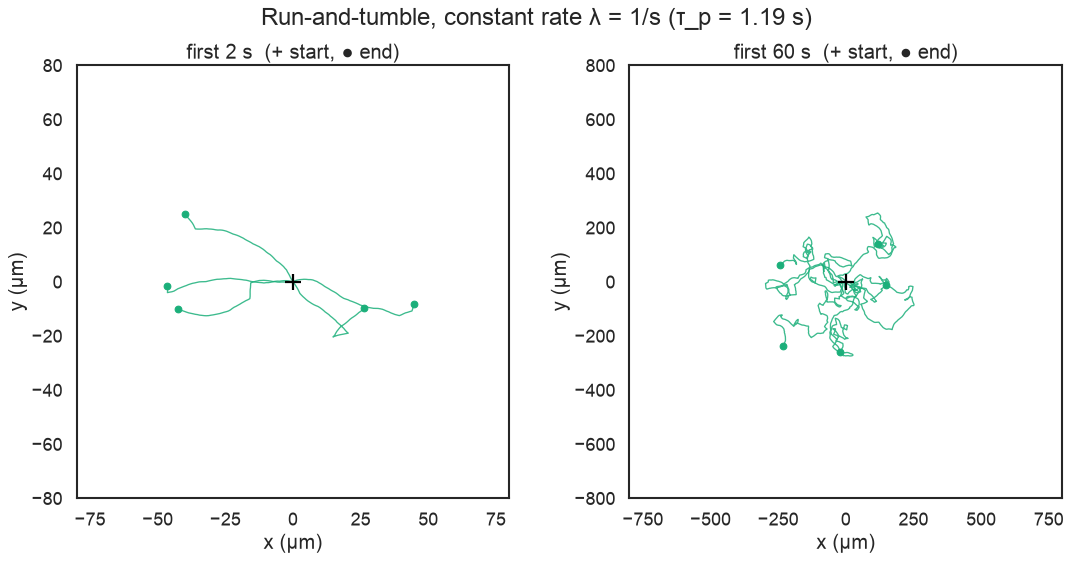

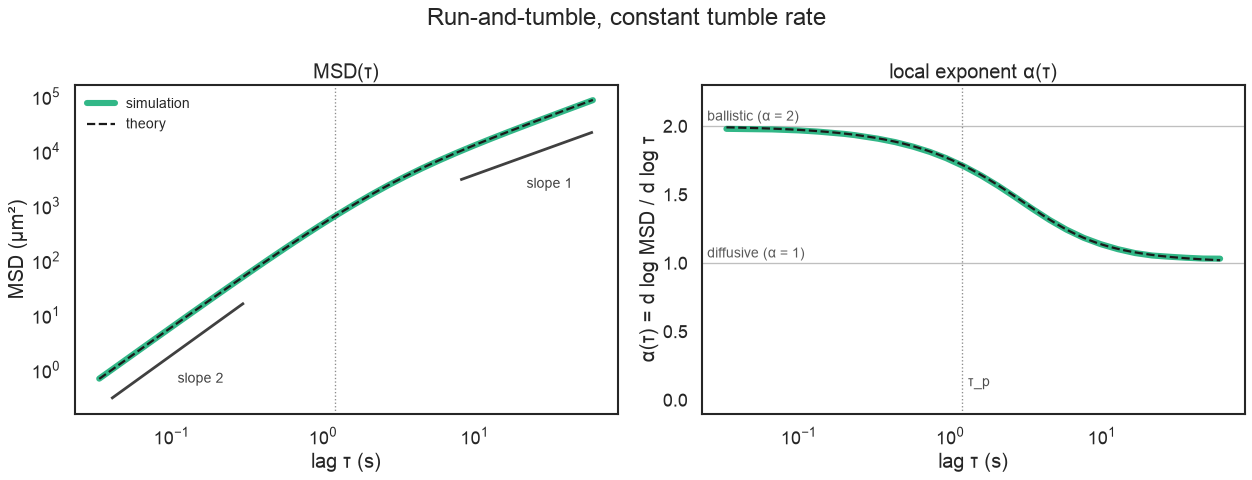

In [4]:
sim_rt = lambda: sim.simulate_run_tumble(BATCH, T, FPS, rng, **SWIM)[0]
tracks_rt = sim_rt()
plotting.plot_tracks(tracks_rt, FPS, COLORS["run_tumble"], f"Run-and-tumble, constant rate λ = {LAM:.0f}/s (τ_p = {TAU_P:.2f} s)")

msd_rt = msd_of(sim_rt)
plotting.msd_figure([(TAU, msd_rt, STYLE["run_tumble"], "simulation")],
                    theory=[(TAU_FINE, an.msd_persistent(TAU_FINE, V, TAU_P), "theory")],
                    vlines=[(TAU_P, "τ_p")], slopes=[(2, 0.04, 0.3), (1, 8, 60)],
                    title="Run-and-tumble, constant tumble rate")

### 🔧 Try it 1 · Move the bend
> The bend of the run-and-tumble MSD sits at the persistence time $\tau_p$. Before running:
> 1. Compute $\tau_p$ from the formula for `LAM_TRY = 3` (three tumbles per second). Which way does the bend move?
> 2. Set `TURN_TRY = (180, 10)`: a reversal, as in *V. cholerae*. $\langle\cos\varphi\rangle$ is now about $-1$. What does that do to $\tau_p$, and to $D_\text{eff}$?
>
> Then run and check against the printed $\tau_p$ and the dotted line on the $\alpha$ panel.

In [5]:
LAM_TRY = 3.0            # 🔧 tumble rate (1/s). Try 0.3 and 3
TURN_TRY = (68.0, 36.0)  # 🔧 turn angle: mean and standard deviation (degrees). Try (180, 10): a reversal

<cos φ> = 0.31,  τ_p = 0.45 s,  D_eff = 140 µm²/s   (section 3: τ_p = 1.19 s, D_eff = 371 µm²/s)


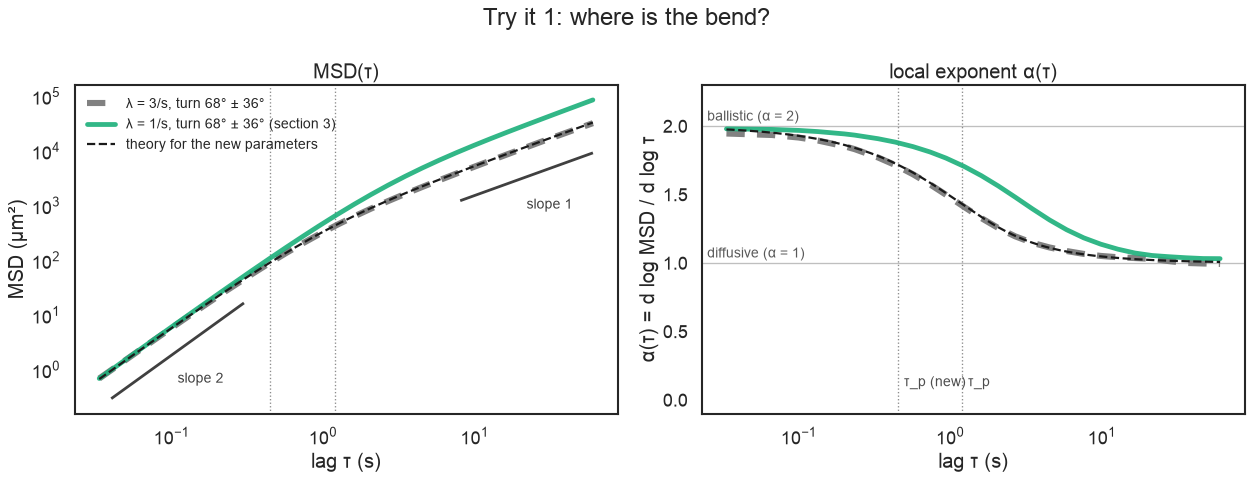

In [6]:
cos_try = sim.turn_angle_cos(TURN_TRY)
tau_p_try = 1 / (LAM_TRY * (1 - cos_try) + DR)
print(f"<cos φ> = {cos_try:.2f},  τ_p = {tau_p_try:.2f} s,  D_eff = {V**2 * tau_p_try / 2:.0f} µm²/s   (section 3: τ_p = {TAU_P:.2f} s, D_eff = {D_EFF:.0f} µm²/s)")
msd_try = an.msd_many(lambda: sim.simulate_run_tumble(BATCH, T, FPS, rng, **dict(SWIM, run_rate=LAM_TRY, turn_angle=TURN_TRY))[0], LAGS, 3)
plotting.msd_figure([(TAU, msd_try, GRAY, f"λ = {LAM_TRY:g}/s, turn {TURN_TRY[0]:g}° ± {TURN_TRY[1]:g}°"),
                     (TAU, msd_rt, STYLE["run_tumble"], f"λ = {LAM:g}/s, turn {TURN[0]:g}° ± {TURN[1]:g}° (section 3)")],
                    theory=[(TAU_FINE, an.msd_persistent(TAU_FINE, V, tau_p_try), "theory for the new parameters")],
                    vlines=[(tau_p_try, "τ_p (new)"), (TAU_P, "τ_p")], slopes=[(2, 0.04, 0.3), (1, 8, 60)],
                    title="Try it 1: where is the bend?")

## 4 · Run-and-tumble with OU switching (numerical)

In real *E. coli* the tumble rate of one cell follows a signaling protein (CheY-P) that fluctuates slowly. We let the rate drift:
$$\lambda(t)=\lambda_0\,e^{\,x(t)-\sigma^2/2},\qquad dx=-\frac{x}{\tau_x}\,dt+\sigma\sqrt{\frac{2}{\tau_x}}\;dW .$$
$x(t)$ is an **Ornstein–Uhlenbeck (OU) process**: a random signal with standard deviation $\sigma$ that forgets its value after a correlation time $\tau_x$. The factor $e^{-\sigma^2/2}$ keeps the average rate at $\lambda_0$. With $\sigma=1$ and $\tau_x=10$ s, the rate of one cell varies several-fold over tens of seconds: **variability within one individual over time**.

**MSD.** There is no simple formula now, so we simulate: the same speed, turns and average rate as in section 3, only the slow fluctuations of the rate are new.

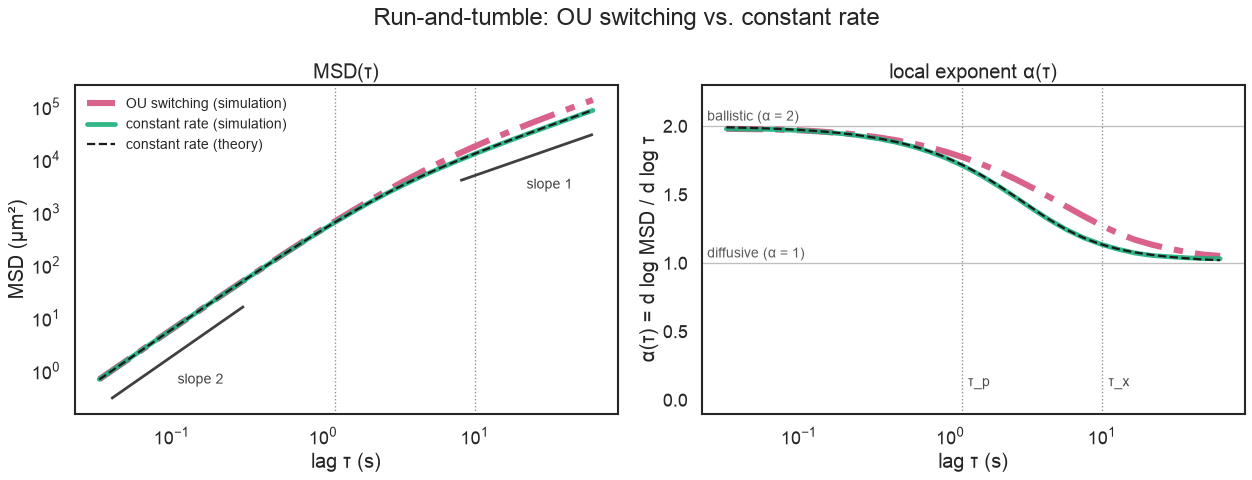

long-time spreading, MSD/(4τ) at τ = 60 s:  OU 567 µm²/s, constant rate 360 µm²/s


In [7]:
sim_ou = lambda: sim.simulate_run_tumble(BATCH, T, FPS, rng, ou_sigma=OU_SIGMA, ou_tau=OU_TAU, **SWIM)
tracks_ou, events_ou, _ = sim_ou()

msd_ou = msd_of(lambda: sim_ou()[0])
plotting.msd_figure([(TAU, msd_ou, STYLE["ou"], "OU switching (simulation)"),
                     (TAU, msd_rt, STYLE["run_tumble"], "constant rate (simulation)")],
                    theory=[(TAU_FINE, an.msd_persistent(TAU_FINE, V, TAU_P), "constant rate (theory)")],
                    vlines=[(TAU_P, "τ_p"), (OU_TAU, "τ_x")], slopes=[(2, 0.04, 0.3), (1, 8, 60)],
                    title="Run-and-tumble: OU switching vs. constant rate")
print(f"long-time spreading, MSD/(4τ) at τ = {TAU[-1]:.0f} s:  OU {msd_ou[-1] / (4 * TAU[-1]):.0f} µm²/s, "
      f"constant rate {msd_rt[-1] / (4 * TAU[-1]):.0f} µm²/s")

With OU switching the cells spread **faster** and stay superdiffusive ($\alpha>1$) up to lags of order $\tau_x$, long after a constant-rate swimmer has become diffusive.

**Why?** Seen from far away, each run is one step of length $\ell\approx vt$, and a random walk of such steps spreads with $D_\text{eff}\approx\langle\ell^2\rangle/(4\langle t\rangle)$. Both models have the same *mean* run, but OU switching produces many more long runs, from periods when a cell's rate is low, and $\langle\ell^2\rangle$ is dominated by them:

constant rate : mean run 0.99 s,  <t²> = 1.93 s²,  longest 11 s
OU switching  : mean run 1.05 s,  <t²> = 4.46 s²,  longest 37 s


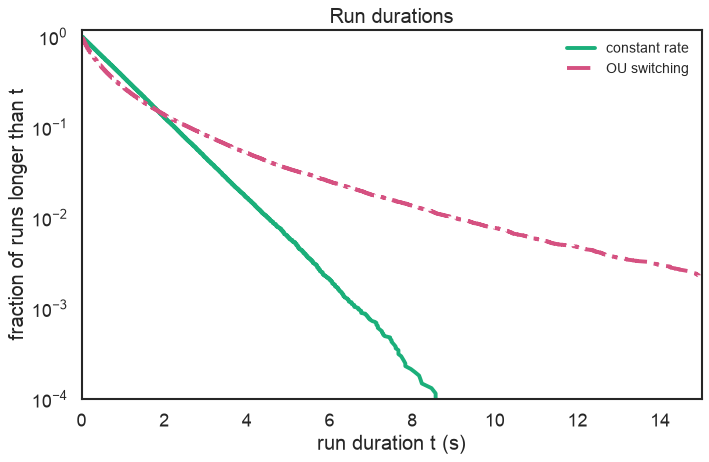

In [8]:
_, events_rt, _ = sim.simulate_run_tumble(BATCH, T, FPS, rng, **SWIM)
runs = {"constant rate": an.run_durations(events_rt, FPS), "OU switching": an.run_durations(events_ou, FPS)}

fig, ax = plt.subplots(figsize=(10, 6))
for (label, r), key in zip(runs.items(), ["run_tumble", "ou"]):
    ts = np.sort(r)
    ax.semilogy(ts, 1 - np.arange(len(ts)) / len(ts), lw=3.5, label=label, **STYLE[key])
    print(f"{label:14s}: mean run {r.mean():.2f} s,  <t²> = {np.mean(r**2):.2f} s²,  longest {r.max():.0f} s")
ax.set(xlabel="run duration t (s)", ylabel="fraction of runs longer than t", xlim=(0, 15), ylim=(1e-4, 1.2),
       title="Run durations")
ax.legend(fontsize="x-small")
plt.show()

### 🔧 Try it 2 · Predict, then run
> Before running, write down:
> 1. `OU_SIGMA_TRY = 0.5` halves the size of the rate fluctuations. Does the long-lag MSD go up or down compared with σ = 1?
> 2. Then `OU_SIGMA_TRY = 2`. And then `OU_TAU_TRY = 0.3` s, a rate that fluctuates much faster than a run lasts: which curve will it resemble?
>
> Run after each prediction. The same experiment on the orientation autocorrelation is Try it 5 of NB1.

In [9]:
OU_SIGMA_TRY, OU_TAU_TRY = 0.5, 10.0   # 🔧 size σ and correlation time τ_x (s) of the rate fluctuations. Try σ = 2; then τ_x = 0.3

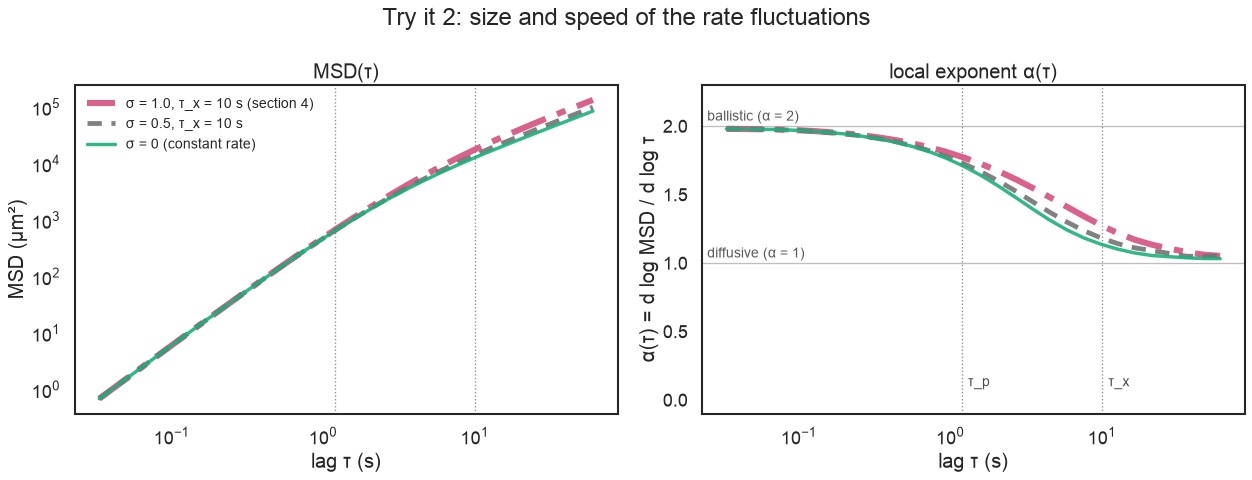

In [10]:
msd_try = an.msd_many(lambda: sim.simulate_run_tumble(BATCH, T, FPS, rng, ou_sigma=OU_SIGMA_TRY, ou_tau=OU_TAU_TRY, **SWIM)[0], LAGS, 3)
plotting.msd_figure([(TAU, msd_ou, STYLE["ou"], f"σ = {OU_SIGMA}, τ_x = {OU_TAU:g} s (section 4)"),
                     (TAU, msd_try, GRAY, f"σ = {OU_SIGMA_TRY}, τ_x = {OU_TAU_TRY:g} s"),
                     (TAU, msd_rt, STYLE["run_tumble"], "σ = 0 (constant rate)")],
                    vlines=[(TAU_P, "τ_p"), (OU_TAU_TRY, "τ_x")], title="Try it 2: size and speed of the rate fluctuations")

## 5 · Biased random walk (analytic and numerical)

The simplest biased walk adds a constant drift $\mathbf v_d$ to diffusion, $\mathbf r_{n+1}=\mathbf r_n+\mathbf v_d\,\Delta t+\sqrt{2D\,\Delta t}\;\boldsymbol\xi_n$. The drift parts of all steps point the same way and add *coherently*, $(Nv_d\Delta t)^2=v_d^2\tau^2$, while the random parts still give $4D\tau$:
$$\boxed{\mathrm{MSD}(\tau)=4D\tau+v_d^2\tau^2}.$$
The two terms are equal at the **crossover time** $\tau_c=4D/v_d^2$: diffusive below it, ballistic above it.

*E. coli* has no drift knob. It biases its random walk by **tumbling less when it happens to swim up the gradient**:
$$\lambda(\theta)=\lambda\,(1-\varepsilon\cos\theta)\quad(\text{gradient toward }+x).$$
Runs up the gradient last longer, so on average the cell drifts toward the attractant. We simulate this swimmer, measure its drift speed $v_d$ from the mean displacement, and compare its MSD with the persistent-walk MSD of section 3 plus the drift term $v_d^2\tau^2$.

measured drift speed v_d = 7.9 µm/s  (31% of the swimming speed)


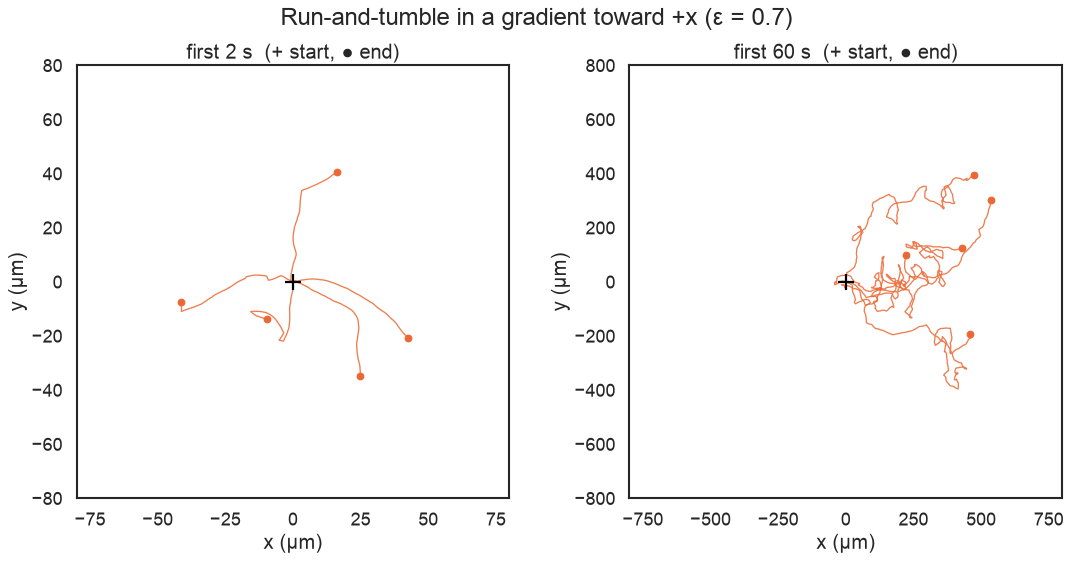

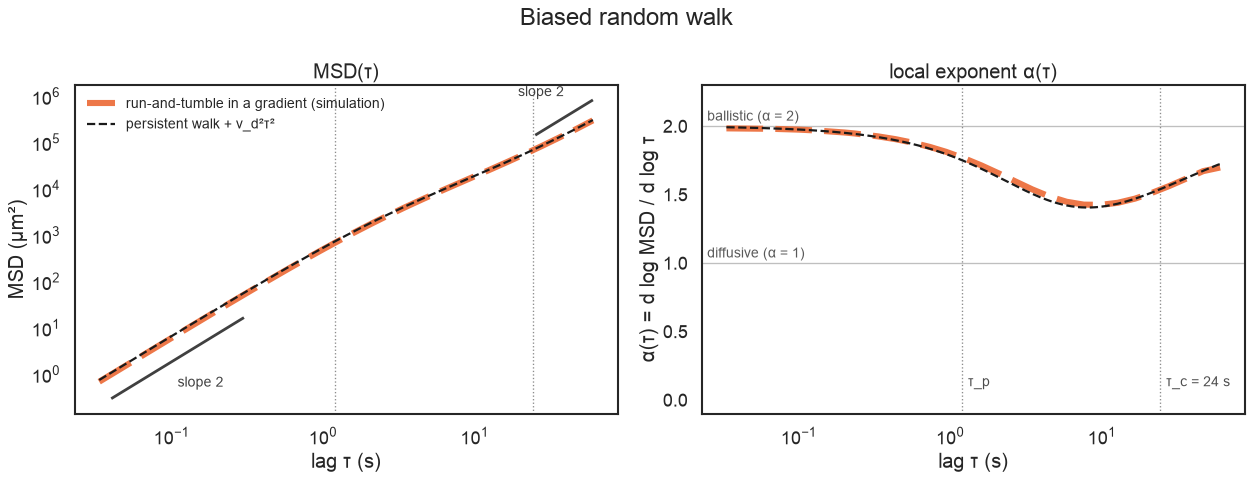

In [11]:
sim_g = lambda: sim.simulate_run_tumble(BATCH, T, FPS, rng, gradient=GRADIENT, **SWIM)[0]
tracks_g = sim_g()
VD = tracks_g[:, -1, 0].mean() / T
print(f"measured drift speed v_d = {VD:.1f} µm/s  ({VD / V:.0%} of the swimming speed)")
plotting.plot_tracks(tracks_g, FPS, COLORS["biased"], f"Run-and-tumble in a gradient toward +x (ε = {GRADIENT})")

msd_g = msd_of(sim_g)
tau_c = 4 * D_EFF / VD**2
plotting.msd_figure([(TAU, msd_g, STYLE["biased"], "run-and-tumble in a gradient (simulation)")],
                    theory=[(TAU_FINE, an.msd_persistent(TAU_FINE, V, TAU_P) + VD**2 * TAU_FINE**2, "persistent walk + v_d²τ²")],
                    vlines=[(TAU_P, "τ_p"), (tau_c, f"τ_c = {tau_c:.0f} s")],
                    slopes=[(2, 0.04, 0.3), (2, 25, 60, 2)],
                    title="Biased random walk")

The chemotactic swimmer has **three** regimes: ballistic below $\tau_p$ (it swims straight), nearly diffusive between $\tau_p$ and $\tau_c$ (its direction is randomized), and ballistic again above $\tau_c$ (the drift wins). Plain drift plus diffusion, $4D_\text{eff}\tau+v_d^2\tau^2$, would miss the first regime, because it has no persistence.

## 6 · All models side by side

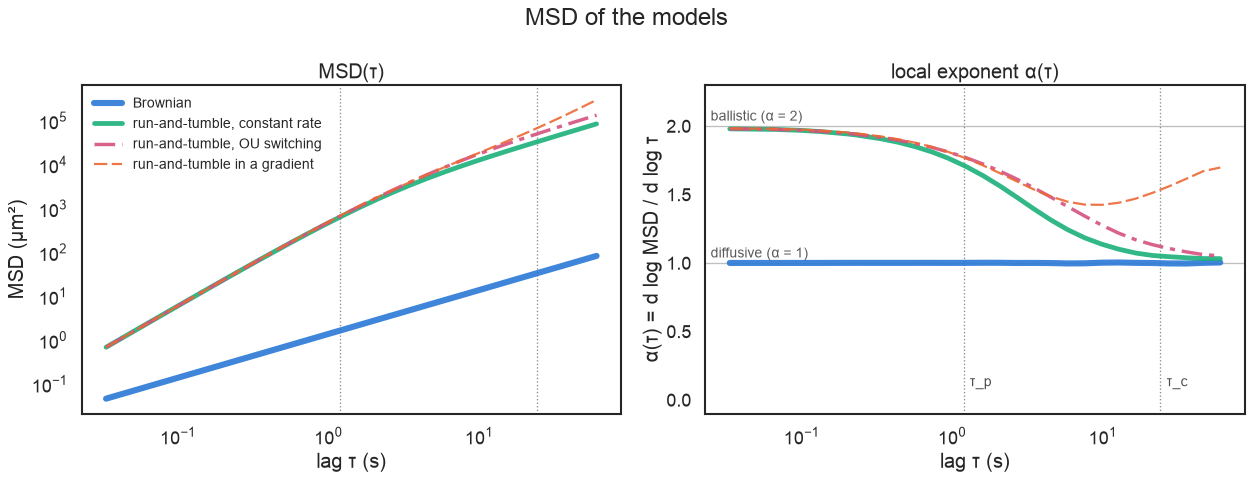

In [12]:
plotting.msd_figure([(TAU, msd_b, STYLE["brownian"], "Brownian"),
                     (TAU, msd_rt, STYLE["run_tumble"], "run-and-tumble, constant rate"),
                     (TAU, msd_ou, STYLE["ou"], "run-and-tumble, OU switching"),
                     (TAU, msd_g, STYLE["biased"], "run-and-tumble in a gradient")],
                    vlines=[(TAU_P, "τ_p"), (tau_c, "τ_c")], title="MSD of the models")

| model | short lags | long lags | $\alpha(\tau)$ |
|---|---|---|---|
| Brownian | $4D\tau$ | $4D\tau$ | 1 |
| run-and-tumble, constant rate | $v^2\tau^2$ | $4D_\text{eff}\tau$, $D_\text{eff}=v^2\tau_p/2$ | 2 → 1 around $\tau_p$ |
| run-and-tumble, OU switching | $v^2\tau^2$ | larger $D_\text{eff}$, reached only after $\sim\tau_x$ | 2 → 1, slower |
| run-and-tumble in a gradient | $v^2\tau^2$ | $v_d^2\tau^2$ | 2 → ~1 → 2 |

## 7 · From models to data

The synthetic datasets (`data/synthetic`) contain the same kinds of cells, measured like real data: tracks of about 10 s, localization noise $\sigma$, tumbles that take time, cells with different speeds. What can their MSD tell us?

### 7a · Non-swimming cells: measure $D$ and the localization noise
Localization noise adds the same error to every displacement, whatever the lag. Each displacement has noise from both ends, so
$$\mathrm{MSD}_\text{measured}(\tau)=4D\tau+4\sigma^2 .$$
A straight-line fit of the MSD against $\tau$ gives $D$ from the slope and $\sigma$ from the intercept.

fit: D = 0.35 µm²/s, σ = 0.20 µm   (true: D = 0.35, σ = 0.2)


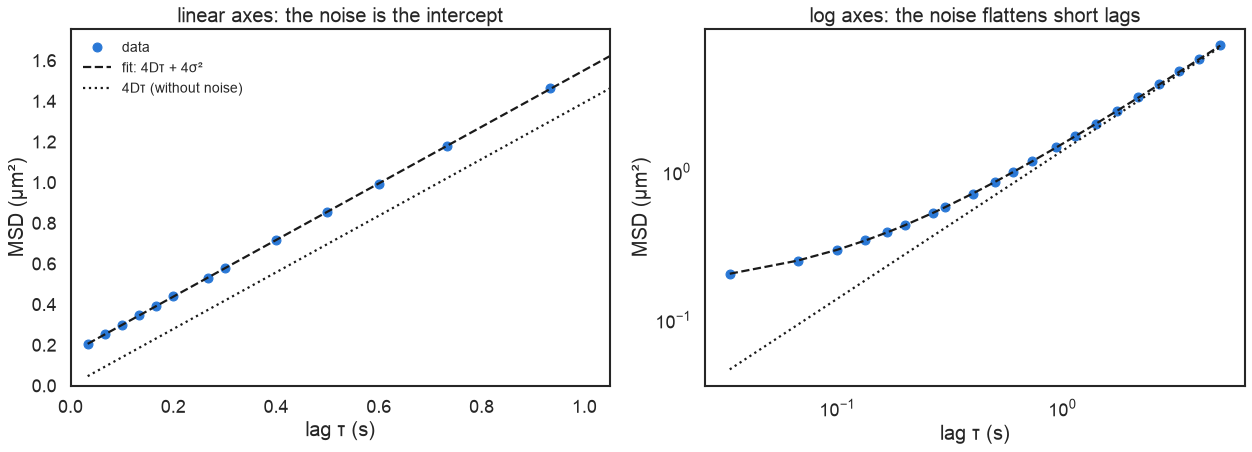

In [13]:
datasets = {name: io.load_dataset(name) for name in ["brownian", "run_tumble", "biased_run_tumble"]}
lags_d = an.log_lags(int(5 * FPS), 25)                 # tracks are short: lags up to 5 s
tau_d = lags_d / FPS
msd_data = {name: an.msd(an.track_arrays(d), lags_d) for name, (d, m) in datasets.items()}

FIT_MAX_S = 1.0                                        # fit the straight line to lags up to 1 s
sel = tau_d <= FIT_MAX_S
slope, intercept = np.polyfit(tau_d[sel], msd_data["brownian"][sel], 1)
D_fit, sigma_fit = slope / 4, np.sqrt(intercept / 4)
meta_b = datasets["brownian"][1]
print(f"fit: D = {D_fit:.2f} µm²/s, σ = {sigma_fit:.2f} µm   "
      f"(true: D = {meta_b['model_parameters']['D']}, σ = {meta_b['localization_noise_um']})")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))
for ax in (ax1, ax2):
    ax.plot(tau_d, msd_data["brownian"], "o", ms=8, color=COLORS["brownian"], label="data")
    ax.plot(tau_d, 4 * D_fit * tau_d + 4 * sigma_fit**2, ls="--", label="fit: 4Dτ + 4σ²", **THEORY_KW)
    ax.plot(tau_d, 4 * D_fit * tau_d, ls=":", label="4Dτ (without noise)", **THEORY_KW)
    ax.set(xlabel="lag τ (s)", ylabel="MSD (µm²)")
ax1.set(xlim=(0, 1.05), ylim=(0, 1.2 * msd_data["brownian"][sel].max()), title="linear axes: the noise is the intercept")
ax2.set(xscale="log", yscale="log", title="log axes: the noise flattens short lags")
ax1.legend(fontsize="x-small")
fig.tight_layout()
plt.show()

On log axes the noise makes the MSD look *flat* at short lags ($\alpha<1$), which could be mistaken for confined or "subdiffusive" motion. Always check the intercept.

### 7b · Swimmers: what short tracks can and cannot show

The same analysis on the swimmer datasets gives the ballistic-to-diffusive bend near $\tau_p$, slightly *more* ballistic than the section 3 formula because real tumbles take 0.15 s and cells differ in speed. But the tracks end at about 10 s, close to $\tau_p$ and far below the crossover time $\tau_c$ of tens of seconds, so the drift term $v_d^2\tau^2$ never dominates: the MSD of the biased population looks almost the same as the unbiased one. The bias is obvious in a different statistic, the **mean** displacement: the `biased_run_tumble` cells drift at about 6 µm/s toward $+x$, the `run_tumble` cells do not drift at all. The MSD is one fingerprint of a strategy, not the whole hand.

## 8 · Going further (optional)

<details>
<summary><b>The exact MSD from the velocity autocorrelation</b></summary>

Write the displacement as an integral of the velocity, $\Delta\mathbf r(\tau)=\int_0^\tau\mathbf v(t)\,dt$. Then
$$\mathrm{MSD}(\tau)=\int_0^\tau\!\!\int_0^\tau\langle\mathbf v(t)\cdot\mathbf v(t')\rangle\,dt\,dt'=2\int_0^\tau(\tau-s)\,C_v(s)\,ds .$$
This is the continuous version of the double sum in section 1. With $C_v(s)=v^2e^{-s/\tau_p}$ it gives the boxed formula of section 3; with $C_v(s)=4D\,\delta(s)$ (no memory) it gives $4D\tau$. The velocity autocorrelation of NB1 and the MSD carry the same information.
</details>

<details>
<summary><b>Fokker–Planck: the population view</b></summary>

Instead of following one cell, ask for the density $P(\mathbf r,t)$ of many cells. For drift plus diffusion,
$$\partial_tP=-\mathbf v_d\cdot\nabla P+D\nabla^2P .$$
From a point, the solution is a Gaussian whose center moves at $\mathbf v_d$ and whose variance grows as $4Dt$, which reproduces the MSD of section 5. The population view is useful when the drift depends on position (a real gradient), with walls, or when cells change the chemical field themselves (the Keller–Segel model).
</details>

## 9 · Questions

1. A dataset's MSD has $\alpha\approx2$ at every lag you can measure. Which models could have produced it? What other measurement would separate them?
2. Two swimmer populations have the same mean run duration. One has a much larger $D_\text{eff}$. What could be different about their runs?
3. From the MSD of a non-swimming population you find $\sigma=0.5$ µm. What does that do to the speeds you computed in NB1?
4. How long would tracks need to be to see the crossover time $\tau_c$ of the biased walk in section 5?